# Part 1 analysis

## Setup

In [17]:
import os
os.chdir("/home/jovyan/work")

In [18]:
from pyspark.sql import SparkSession, functions as F
from pyspark.sql.types import StructType, StructField, IntegerType, StringType
import pandas as pd
import matplotlib.pyplot as plt

spark = (
    SparkSession.builder
    .appName("analysis_notebook")
    .config("spark.driver.memory", "6g")
    .config("spark.sql.shuffle.partitions", "8")
    .getOrCreate()
)
print("driver.memory:", spark.sparkContext.getConf().get("spark.driver.memory", "NOT SET"))
spark

driver.memory: 6g


## Step 1: load the joined table and attach region

In [19]:
POLLUTANTS = ["pm25", "pm10", "no2", "o3"]
WEATHER_VARS = ["temperature_2m", "relative_humidity_2m", "precipitation", "wind_speed_10m"]

joined = spark.read.parquet("data/processed/openaq_weather_joined")
total_rows = joined.count()
print("Joined rows:", total_rows)

departments_schema = StructType([
    StructField("location_id", IntegerType(), True),
    StructField("commune", StringType(), True),
    StructField("insee_code", StringType(), True),
    StructField("department", StringType(), True),
])
departments = spark.read.schema(departments_schema).option("header", True).csv("config/station_departments.csv")

data = joined.join(departments, "location_id", "left").withColumn(
    "region",
    F.when(F.col("department") == "75", "Paris")
    .when(F.col("department").isin("92", "93", "94"), "Petite couronne")
    .when(F.col("department").isin("77", "78", "91", "95"), "Grande couronne")
    .otherwise("Hors Ile-de-France"),
)
print("Rows with no matched department:", data.filter(F.col("department").isNull()).count())
data.groupBy("region").count().orderBy("region").show()

Joined rows: 4072187
Rows with no matched department: 0
+------------------+-------+
|            region|  count|
+------------------+-------+
|   Grande couronne|1184342|
|Hors Ile-de-France|1464554|
|             Paris| 704307|
|   Petite couronne| 718984|
+------------------+-------+



## Step 1b: which stations actually have all 4 pollutants

In [ ]:

station_region = data.select("location_id", "region").distinct()
station_pollutant = data.groupBy("location_id").agg(
    *[F.max(F.col(p).isNotNull().cast("int")).alias(f"has_{p}") for p in POLLUTANTS]
)
coverage_by_region = station_region.join(station_pollutant, "location_id").groupBy("region").agg(
    F.count(F.lit(1)).alias("stations"),
    *[F.sum(f"has_{p}").alias(f"{p}_stations") for p in POLLUTANTS],
)
coverage_by_region.orderBy("region").show()

full_coverage_stations = [
    r["location_id"] for r in station_pollutant.filter(
        sum(F.col(f"has_{p}") for p in POLLUTANTS) == 4
    ).select("location_id").collect()
]
print(f"Stations with all 4 pollutants: {len(full_coverage_stations)}")

data.createOrReplaceTempView("data")
data_full = data.filter(F.col("location_id").isin(full_coverage_stations))
data_full.createOrReplaceTempView("data_full_coverage")

+------------------+--------+-------------+-------------+------------+-----------+
|            region|stations|pm25_stations|pm10_stations|no2_stations|o3_stations|
+------------------+--------+-------------+-------------+------------+-----------+
|   Grande couronne|      22|            9|           10|          12|         15|
|Hors Ile-de-France|      51|           28|           39|          40|         31|
|             Paris|      17|            8|           10|          17|          5|
|   Petite couronne|      15|            6|            9|          14|          5|
+------------------+--------+-------------+-------------+------------+-----------+

Stations with all 4 pollutants: 20


## Part A: time-of-day patterns

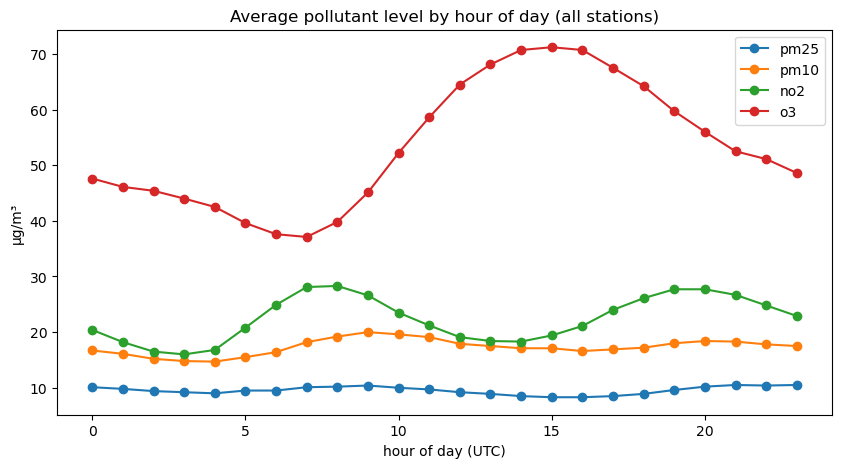

,pm25,pm10,no2,o3
hour,,,,
0,10.1,16.7,20.4,47.6
1,9.8,16.1,18.2,46.1
2,9.4,15.2,16.5,45.4
3,9.2,14.8,16.0,44.0
4,9.0,14.7,16.8,42.5
5,9.5,15.5,20.8,39.6
6,9.5,16.4,24.9,37.6
7,10.1,18.2,28.1,37.1
8,10.2,19.2,28.3,39.8


In [21]:
hourly = (
    data.withColumn("hour", F.hour("datetime_utc"))
    .groupBy("hour")
    .agg(*[F.round(F.avg(p), 1).alias(p) for p in POLLUTANTS])
    .orderBy("hour")
    .toPandas()
    .set_index("hour")
)
hourly.plot(figsize=(10, 5), marker="o", title="Average pollutant level by hour of day (all stations)")
plt.xlabel("hour of day (UTC)")
plt.ylabel("\u00b5g/m\u00b3")
plt.show()
hourly

## Part A: weather correlation

In [22]:
corr_rows = []
for p in POLLUTANTS:
    row = {"pollutant": p}
    for w in WEATHER_VARS:
        row[w] = data.select(F.corr(p, w)).first()[0]
    corr_rows.append(row)

corr_table = pd.DataFrame(corr_rows).set_index("pollutant").round(3)
corr_table

,temperature_2m,relative_humidity_2m,precipitation,wind_speed_10m
pollutant,,,,
pm25,-0.195,0.060,-0.079,-0.203
pm10,-0.015,-0.114,-0.107,-0.202
no2,-0.165,0.073,-0.040,-0.258
o3,0.559,-0.673,0.003,0.203


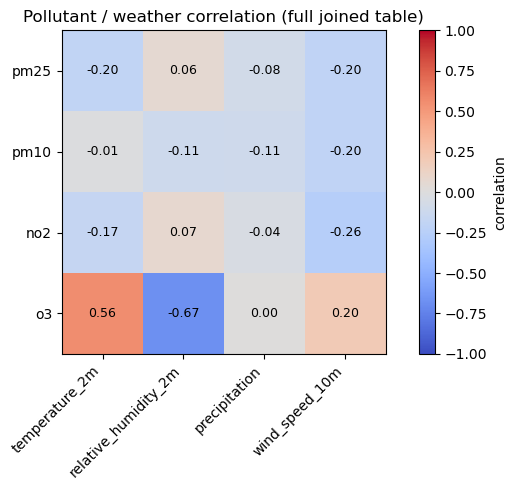

In [23]:
plt.figure(figsize=(7, 5))
plt.imshow(corr_table, cmap="coolwarm", vmin=-1, vmax=1)
plt.colorbar(label="correlation")
plt.xticks(range(len(WEATHER_VARS)), WEATHER_VARS, rotation=45, ha="right")
plt.yticks(range(len(POLLUTANTS)), POLLUTANTS)
for i in range(len(POLLUTANTS)):
    for j in range(len(WEATHER_VARS)):
        plt.text(j, i, f"{corr_table.iloc[i, j]:.2f}", ha="center", va="center", fontsize=9)
plt.title("Pollutant / weather correlation (full joined table)")
plt.tight_layout()
plt.show()

### Does the weather relationship vary by station?

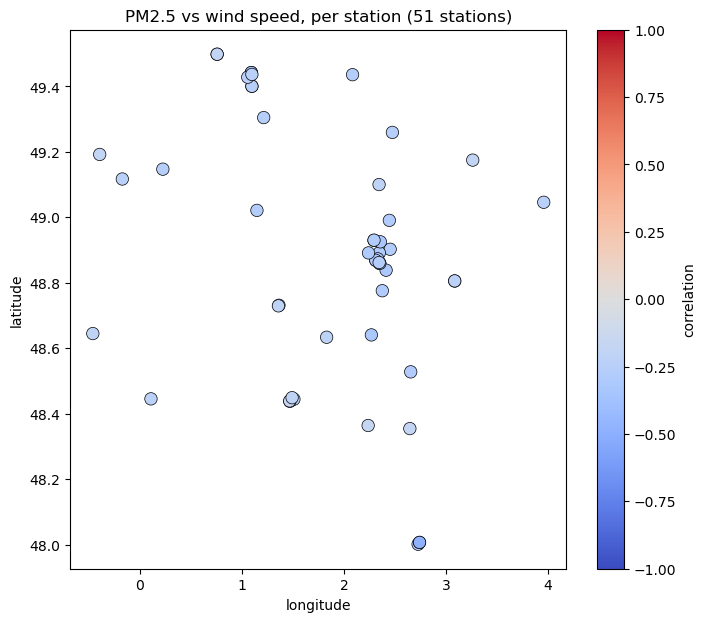

In [24]:
def station_correlation_map(pollutant, weather_var, title):
    per_station = (
        data.groupBy("location_id", "station_latitude", "station_longitude")
        .agg(F.corr(pollutant, weather_var).alias("correlation"), F.count(F.lit(1)).alias("rows"))
        .filter(F.col("correlation").isNotNull())
        .toPandas()
    )
    plt.figure(figsize=(8, 7))
    sc = plt.scatter(
        per_station["station_longitude"], per_station["station_latitude"],
        c=per_station["correlation"], cmap="coolwarm", vmin=-1, vmax=1,
        s=80, edgecolors="black", linewidths=0.5,
    )
    plt.colorbar(sc, label="correlation")
    plt.xlabel("longitude")
    plt.ylabel("latitude")
    plt.title(f"{title} ({len(per_station)} stations)")
    plt.show()
    return per_station


pm25_wind_map = station_correlation_map("pm25", "wind_speed_10m", "PM2.5 vs wind speed, per station")

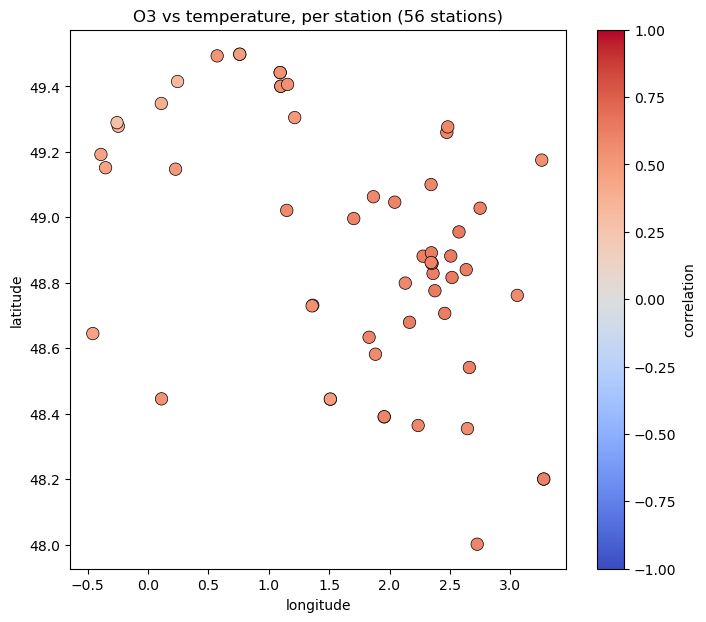

In [25]:
o3_temp_map = station_correlation_map("o3", "temperature_2m", "O3 vs temperature, per station")

### Correlation by department


In [ ]:
dept_corr_by_weather = {}
for w in WEATHER_VARS:
    dept_corr_by_weather[w] = (
        data.groupBy("department")
        .agg(*[F.corr(p, w).alias(p) for p in POLLUTANTS])
        .filter(F.col("department").isNotNull())
        .toPandas()
        .set_index("department")
        .sort_index()
    )

n_depts = len(dept_corr_by_weather[WEATHER_VARS[0]])
print(f"Departments represented: {n_depts}")

fig, axes = plt.subplots(2, 2, figsize=(13, max(6, 0.45 * n_depts)))
im = None
for ax, w in zip(axes.flatten(), WEATHER_VARS):
    df = dept_corr_by_weather[w]
    im = ax.imshow(df, cmap="coolwarm", vmin=-1, vmax=1, aspect="auto")
    ax.set_xticks(range(len(POLLUTANTS)))
    ax.set_xticklabels(POLLUTANTS)
    ax.set_yticks(range(len(df)))
    ax.set_yticklabels(df.index)
    ax.set_title(w)
    for i in range(len(df)):
        for j in range(len(POLLUTANTS)):
            v = df.iloc[i, j]
            if pd.notna(v):
                ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=7)

fig.colorbar(im, ax=axes, label="correlation", shrink=0.8)
plt.suptitle("Pollutant / weather correlation by department")
plt.show()

## Part A: regional pattern

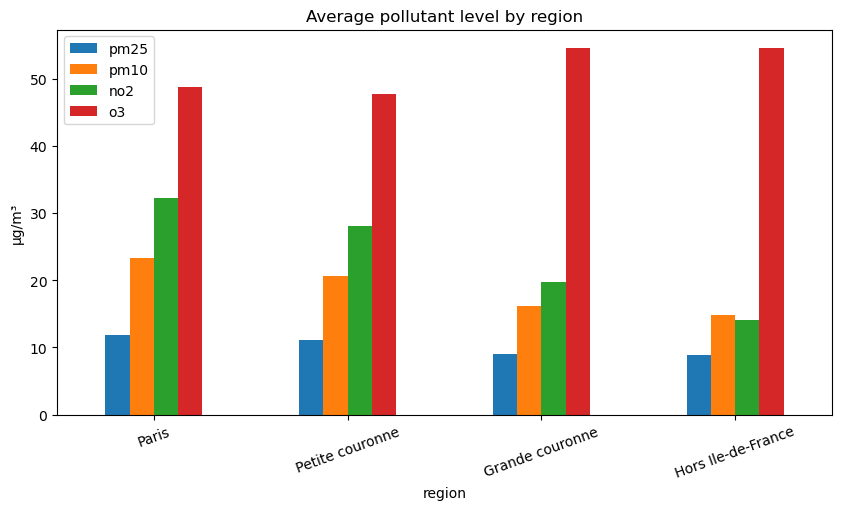

,pm25,pm10,no2,o3
region,,,,
Petite couronne,11.1,20.6,28.0,47.7
Hors Ile-de-France,8.8,14.8,14.0,54.6
Paris,11.9,23.3,32.2,48.8
Grande couronne,9.0,16.1,19.8,54.6


In [26]:
regional = (
    data.groupBy("region")
    .agg(*[F.round(F.avg(p), 1).alias(p) for p in POLLUTANTS])
    .toPandas()
    .set_index("region")
)
regional.loc[["Paris", "Petite couronne", "Grande couronne", "Hors Ile-de-France"]].plot(
    kind="bar", figsize=(10, 5), title="Average pollutant level by region"
)
plt.ylabel("\u00b5g/m\u00b3")
plt.xticks(rotation=20)
plt.show()
regional

### Regional comparison, restricted to the full-coverage stations.

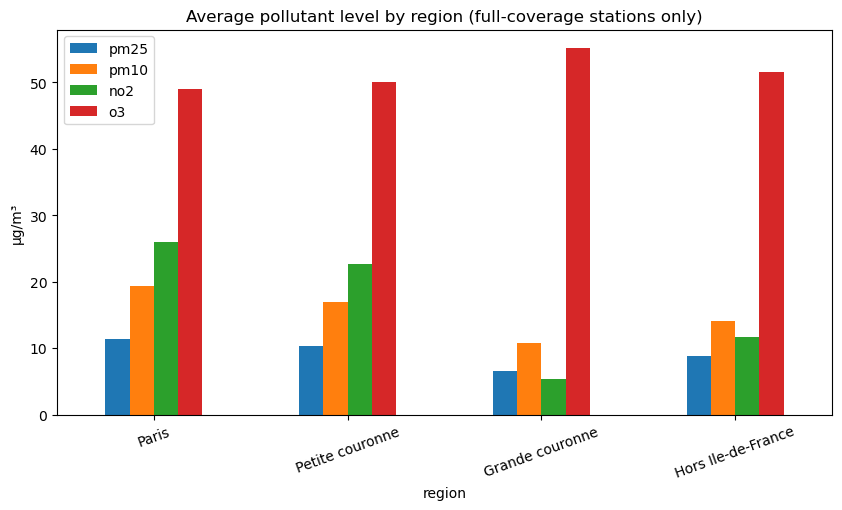

,pm25,pm10,no2,o3,stations
region,,,,,
Petite couronne,10.3,16.9,22.6,50.0,1
Hors Ile-de-France,8.8,14.1,11.6,51.6,14
Paris,11.3,19.3,26.0,49.0,4
Grande couronne,6.5,10.8,5.3,55.2,1


In [27]:
regional_full = spark.sql("""
    SELECT region,
           ROUND(AVG(pm25), 1) AS pm25,
           ROUND(AVG(pm10), 1) AS pm10,
           ROUND(AVG(no2), 1) AS no2,
           ROUND(AVG(o3), 1) AS o3,
           COUNT(DISTINCT location_id) AS stations
    FROM data_full_coverage
    GROUP BY region
""").toPandas().set_index("region")

regional_full.loc[["Paris", "Petite couronne", "Grande couronne", "Hors Ile-de-France"], POLLUTANTS].plot(
    kind="bar", figsize=(10, 5), title="Average pollutant level by region (full-coverage stations only)"
)
plt.ylabel("µg/m³")
plt.xticks(rotation=20)
plt.show()
regional_full

### regional average: equal weight per station


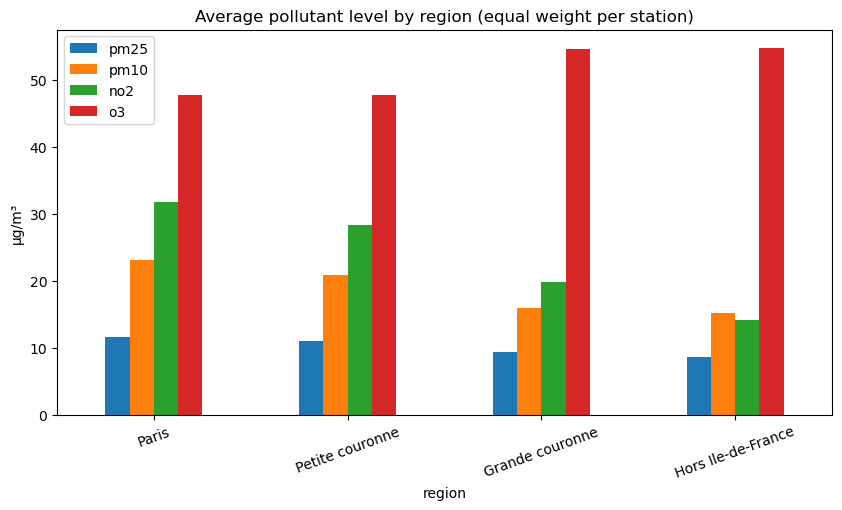

,stations,pm25,pm10,no2,o3
region,,,,,
Petite couronne,15,11.0,20.8,28.3,47.7
Hors Ile-de-France,51,8.6,15.1,14.1,54.8
Paris,17,11.6,23.1,31.8,47.8
Grande couronne,22,9.4,15.9,19.8,54.6


In [ ]:

station_means = data.groupBy("location_id", "region").agg(*[F.avg(p).alias(p) for p in POLLUTANTS])

regional_equal_weight = (
    station_means.groupBy("region")
    .agg(
        F.count(F.lit(1)).alias("stations"),
        *[F.round(F.avg(p), 1).alias(p) for p in POLLUTANTS],
    )
)
regional_equal_weight = regional_equal_weight.toPandas().set_index("region")

regional_equal_weight.loc[["Paris", "Petite couronne", "Grande couronne", "Hors Ile-de-France"], POLLUTANTS].plot(
    kind="bar", figsize=(10, 5), title="Average pollutant level by region (equal weight per station)"
)
plt.ylabel("µg/m³")
plt.xticks(rotation=20)
plt.show()
regional_equal_weight

## Part A: yearly trend

In [ ]:
ALL_YEARS = list(range(2018, 2027))
data_year = data.withColumn("year", F.year("datetime_utc"))

print("Last timestamp in the data:", data.agg(F.max("datetime_utc")).first()[0], "-- 2026 is partial")

stable_stations = {}
for p in POLLUTANTS:
    years_per_station = (
        data_year.filter(F.col(p).isNotNull())
        .select("location_id", "year").distinct()
        .groupBy("location_id").agg(F.countDistinct("year").alias("n_years"))
    )
    ids = [
        r["location_id"] for r in
        years_per_station.filter(F.col("n_years") == len(ALL_YEARS)).select("location_id").collect()
    ]
    stable_stations[p] = ids
    print(f"{p}: {len(ids)} stations present in all 9 years")

Last timestamp in the data: 2026-10-10 23:00:00 -- 2026 is partial
pm25: 15 stations present in all 9 years
pm10: 28 stations present in all 9 years
no2: 40 stations present in all 9 years
o3: 33 stations present in all 9 years


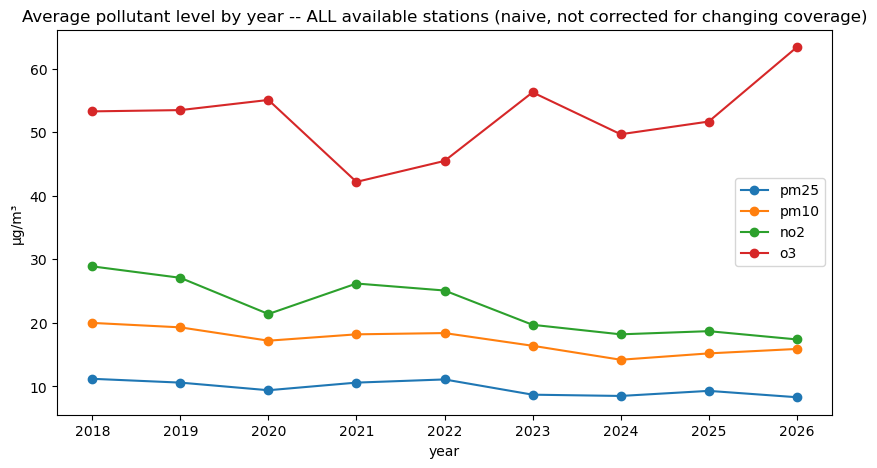

,pm25,pm10,no2,o3
year,,,,
2018,11.2,20.0,28.9,53.3
2019,10.6,19.3,27.1,53.5
2020,9.4,17.2,21.4,55.1
2021,10.6,18.2,26.2,42.2
2022,11.1,18.4,25.1,45.5
2023,8.7,16.4,19.7,56.3
2024,8.5,14.2,18.2,49.7
2025,9.3,15.2,18.7,51.7
2026,8.3,15.9,17.4,63.4


In [30]:
naive_yearly = (
    data_year.groupBy("year")
    .agg(*[F.round(F.avg(p), 1).alias(p) for p in POLLUTANTS])
    .orderBy("year")
    .toPandas()
    .set_index("year")
)
naive_yearly.plot(figsize=(10, 5), marker="o", title="Average pollutant level by year -- ALL available stations (naive, not corrected for changing coverage)")
plt.ylabel("µg/m³")
plt.show()
naive_yearly

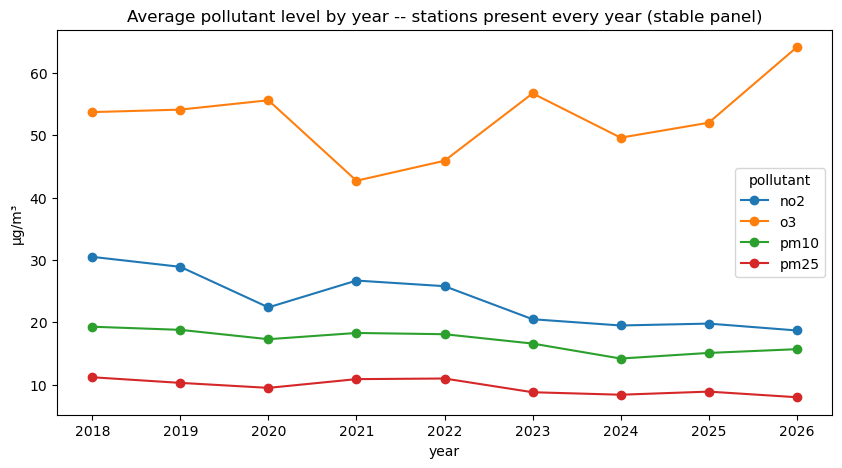

pollutant,no2,o3,pm10,pm25
year,,,,
2018,30.5,53.7,19.3,11.2
2019,28.9,54.1,18.8,10.3
2020,22.4,55.6,17.3,9.5
2021,26.7,42.7,18.3,10.9
2022,25.8,45.9,18.1,11.0
2023,20.5,56.7,16.6,8.8
2024,19.5,49.6,14.2,8.4
2025,19.8,52.0,15.1,8.9
2026,18.7,64.1,15.7,8.0


In [31]:
stable_rows = []
for p in POLLUTANTS:
    ids = stable_stations[p]
    yearly = (
        data_year.filter(F.col(p).isNotNull() & F.col("location_id").isin(ids))
        .groupBy("year")
        .agg(F.round(F.avg(p), 1).alias("value"))
        .toPandas()
    )
    yearly["pollutant"] = p
    stable_rows.append(yearly)

stable_pivot = pd.concat(stable_rows).pivot(index="year", columns="pollutant", values="value")
stable_pivot.plot(figsize=(10, 5), marker="o", title="Average pollutant level by year -- stations present every year (stable panel)")
plt.ylabel("µg/m³")
plt.show()
stable_pivot

## Part B: pollution episodes

In [32]:
EPISODE_THRESHOLDS = {"pm25": 15, "pm10": 45, "no2": 25, "o3": 100}

episode_flags = data
for p, threshold in EPISODE_THRESHOLDS.items():
    episode_flags = episode_flags.withColumn(f"{p}_episode", (F.col(p) > threshold).cast("int"))

episode_flags.agg(
    *[F.sum(f"{p}_episode").alias(f"{p}_episode_hours") for p in POLLUTANTS]
).show()

+------------------+------------------+-----------------+----------------+
|pm25_episode_hours|pm10_episode_hours|no2_episode_hours|o3_episode_hours|
+------------------+------------------+-----------------+----------------+
|            206565|             68469|          1012469|          109074|
+------------------+------------------+-----------------+----------------+



In [33]:
# Rank stations by total episode hours across all 4 pollutants.
episode_flags = episode_flags.withColumn(
    "any_episode", F.greatest(*[F.coalesce(F.col(f"{p}_episode"), F.lit(0)) for p in POLLUTANTS])
)

station_episodes = (
    episode_flags.groupBy("location_id", "station")
    .agg(
        F.count(F.lit(1)).alias("total_hours"),
        *[F.sum(f"{p}_episode").alias(f"{p}_episodes") for p in POLLUTANTS],
        F.sum("any_episode").alias("total_episode_hours"),
    )
    .withColumn("episode_rate_pct", F.round(F.col("total_episode_hours") / F.col("total_hours") * 100, 2))
    .orderBy(F.desc("total_episode_hours"))
)
station_episodes.show(20, truncate=False)

+-----------+--------------------+-----------+-------------+-------------+------------+-----------+-------------------+----------------+
|location_id|station             |total_hours|pm25_episodes|pm10_episodes|no2_episodes|o3_episodes|total_episode_hours|episode_rate_pct|
+-----------+--------------------+-----------+-------------+-------------+------------+-----------+-------------------+----------------+
|4063       |Auto A1 -Saint-Denis|56440      |16309        |10448        |51611       |NULL       |52381              |92.81           |
|4138       |RN20 - MONTLHERY    |55781      |5092         |NULL         |47461       |NULL       |47760              |85.62           |
|4041       |Bld peripherique Est|57430      |14182        |4115         |45097       |NULL       |45779              |79.71           |
|4070       |Boulevard Haussmann |58226      |2387         |2800         |38459       |NULL       |39033              |67.04           |
|4053       |RN2-PANTIN          |50340  

## Part B: 
Compare average weather conditions during episode hours vs. non-episode hours, per pollutant.

In [34]:
comparison_rows = []
for p in POLLUTANTS:
    episode_avg = episode_flags.filter(F.col(f"{p}_episode") == 1).agg(
        *[F.round(F.avg(w), 1).alias(w) for w in WEATHER_VARS]
    ).first()
    normal_avg = episode_flags.filter(F.col(f"{p}_episode") == 0).agg(
        *[F.round(F.avg(w), 1).alias(w) for w in WEATHER_VARS]
    ).first()
    comparison_rows.append({"pollutant": p, "condition": "episode", **episode_avg.asDict()})
    comparison_rows.append({"pollutant": p, "condition": "normal", **normal_avg.asDict()})

pd.DataFrame(comparison_rows).set_index(["pollutant", "condition"])

temperature_2m  relative_humidity_2m  precipitation  \
pollutant condition                                                        
pm25      episode               8.9                  81.6            0.0   
          normal               13.6                  77.2            0.1   
pm10      episode              11.6                  75.7            0.0   
          normal               12.7                  78.1            0.1   
no2       episode              11.0                  80.1            0.1   
          normal               13.8                  76.3            0.1   
o3        episode              25.4                  44.8            0.0   
          normal               11.9                  79.6            0.1   

                     wind_speed_10m  
pollutant condition                  
pm25      episode              10.2  
          normal               13.8  
pm10      episode              10.0  
          normal               13.5  
no2       episode              11.1  
          normal               14.2  
o3        episode              10.9  
          normal               13.5